# BAB 6.3 — DEEP LEARNING MODEL DESIGN & SANITY CHECK (BI-LSTM)

**Mata Kuliah:** Data Science (Semester 5)  
**Proyek:** Analisis Klasifikasi Ujaran Kebencian pada Informasi Pemerintahan Indonesia di Media Sosial Menggunakan Machine Learning dan Deep Learning  
**Keterkaitan SDG:** **SDG 16** (*Peace, Justice and Strong Institutions*) — Target 16.10 & 16.7  
**PIC / Anggota 1:** Ardhana Syah Hidayat (244311037)  
**Kolaborator / Anggota 2:** Muhammad Adam Al-Kidri (244311050)  

---

### Tujuan Notebook:
1. **Pemilihan Jenis DL (Bab 6.3.1):** Menjelaskan alasan pemilihan **Bidirectional LSTM (Bi-LSTM)** untuk pemrosesan sekuens teks media sosial bahasa Indonesia (serta kesiapan opsi *Transfer Learning* IndoBERT pada lingkungan GPU).
2. **Desain Arsitektur & `model.summary()` (Bab 6.3.2):** Merancang arsitektur 2-layer Bi-LSTM + Global Pooling + MLP Head, menjelaskan *Inductive Bias*, dan mencetak ringkasan jumlah parameter model.
3. **Preprocessing Khusus DL (Bab 6.3.3):** Membangun *vocabulary* (hanya dari Train Set), melakukan *integer encoding*, serta *padding/truncation* pada kolom `text_clean_contextual` (kata negasi utuh).
4. **Sanity Check Training Awal (Bab 6.3.5):** Menjalankan 3 *epoch* awal untuk memastikan pipeline *end-to-end* berjalan tanpa *error* dan kurva *loss* menurun konsisten.

## 6.3.1 Pemilihan Jenis Deep Learning & Alasan

Mengacu pada proposal awal (`docs/pengajuan-ide.md`) dan `README.md`, model Deep Learning proyek ini dirancang menggunakan **Bidirectional Long Short-Term Memory (Bi-LSTM)** sebagai jaringan sekuensial lokal (dan opsi *Transfer Learning* **IndoBERT** untuk eksekusi di lingkungan GPU Cloud).

### Alasan Pemilihan Bi-LSTM Berdasarkan Karakteristik Data:
1. **Menangkap Urutan Kata & Negasi (*Sequential Context*):**
   Model berbasis *bag-of-words* (TF-IDF) kehilangan informasi urutan kata. Pada ujaran kebencian bahasa Indonesia, frasa seperti *"tidak pantas menghina"* vs *"pantas dihina"* memiliki makna bertolak belakang. Bi-LSTM memproses token satu per satu secara berurutan sehingga menjaga struktur sintaksis.
2. **Pemahaman Konteks Dua Arah (*Bidirectional*):**
   Dengan membaca kalimat dari kiri-ke-kanan ($\rightarrow$) dan kanan-ke-kiri ($\leftarrow$), representasi setiap kata diperkaya oleh konteks sebelum dan sesudahnya.
3. **Efisiensi Komputasi Lokal:**
   Dengan ±2 juta parameter (jauh lebih ringkas dibanding Transformer 124 juta parameter), Bi-LSTM dapat dilatih dan diuji *sanity check*-nya langsung di CPU lokal tanpa kendala memori atau ruang penyimpanan.

## 6.3.2 Desain Arsitektur, Inductive Bias, & `model.summary()`

### Rancangan Layer (Memenuhi Syarat Minimum $\ge 1$ Layer RNN):
1. **Input Layer:** Sekuens indeks token integer dengan panjang tetap `MAX_LEN = 80`.
2. **Embedding Layer:** Memetakan 10.000 token kosakata menjadi vektor padat berdimensi `128` (`padding_idx=0`), diikuti `Dropout(0.3)`.
3. **2-Layer Bidirectional LSTM:** `hidden_dim = 128` per arah ($2 \times 128 = 256$ fitur kontekstual per langkah waktu) dengan `dropout = 0.3` antar-layer.
4. **Dual Global Pooling (`Mean` + `Max`):** Menggabungkan rata-rata konteks kalimat (256-dim) dan aktivasi sinyal terkuat (256-dim) menjadi representasi kalimat berukuran **512 dimensi**.
5. **Classification Head (MLP):** `Linear(512 -> 128)` $\rightarrow$ `ReLU` $\rightarrow$ `Dropout(0.3)` $\rightarrow$ `Linear(128 -> 2)`.

### Inductive Bias Arsitektur Bi-LSTM:
1. **Bias Sekuensial & Memori Berpintu (*Gated Recurrence*):** Mengasumsikan urutan kemunculan token membawa makna semantik dan gerbang memori (*input, forget, output gates*) dapat menyaring kata penting jangka panjang maupun pendek.
2. **Konteks Dua Arah (*Bidirectionality*):** Mengasumsikan representasi optimal suatu kata bergantung pada kombinasi kata sebelum dan sesudahnya secara simetris.
3. **Invariansi Posisi via Pooling (*Translation Invariance*):** Global Max Pooling mengasumsikan bahwa sinyal frasa kebencian tetap valid terlepas dari apakah frasa tersebut muncul di awal, tengah, atau akhir cuitan.

In [1]:
import time
import json
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch: {torch.__version__} | Device: {device}")

current_dir = Path.cwd()
root_dir = current_dir if (current_dir / 'data').exists() else current_dir.parent
data_dir = root_dir / 'data' / 'processed'
results_dir = root_dir / 'results'
results_dir.mkdir(parents=True, exist_ok=True)

PyTorch: 2.11.0+cpu | Device: cpu


## 6.3.3 Preprocessing Khusus Deep Learning (Bebas Leakage)
* Menggunakan kolom **`text_clean_contextual`** (kata negasi seperti *tidak, bukan, jangan* tetap utuh).
* Kosakata (*vocabulary*) maksimal `10.000` kata dibangun **murni dari Training Set**, dengan token cadangan `<PAD> = 0` dan `<UNK> = 1`.
* Panjang sekuens ditetapkan ke `MAX_LEN = 80` (berdasarkan temuan Bab 5 bahwa maksimum panjang kata pada korpus ini adalah `52` kata, sehingga `80` token menampung seluruh cuitan tanpa pemotongan berarti).

In [2]:
train_df = pd.read_csv(data_dir / 'train.csv', keep_default_na=False)
val_df = pd.read_csv(data_dir / 'val.csv', keep_default_na=False)

# Bangun vocabulary HANYA dari Train Set
counter = Counter()
for text in train_df['text_clean_contextual']:
    counter.update(text.split())

MAX_VOCAB = 10000
MAX_LEN = 80
vocab = {'<PAD>': 0, '<UNK>': 1}
for word, _ in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

def encode_texts(series, max_len=MAX_LEN):
    arr = np.zeros((len(series), max_len), dtype=np.int64)
    for i, text in enumerate(series):
        tokens = text.split()[:max_len]
        for j, tok in enumerate(tokens):
            arr[i, j] = vocab.get(tok, 1)
    return torch.tensor(arr, dtype=torch.long)

X_train_seq = encode_texts(train_df['text_clean_contextual'])
y_train_t = torch.tensor(train_df['HS'].values, dtype=torch.long)
X_val_seq = encode_texts(val_df['text_clean_contextual'])
y_val_t = torch.tensor(val_df['HS'].values, dtype=torch.long)

BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train_seq, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_seq, y_val_t), batch_size=128, shuffle=False)

print(f"Ukuran Vocabulary : {len(vocab):,} token")
print(f"Input Shape Train : {tuple(X_train_seq.shape)}")
print(f"Input Shape Val   : {tuple(X_val_seq.shape)}")

Ukuran Vocabulary : 10,000 token
Input Shape Train : (9105, 80)
Input Shape Val   : (1951, 80)


In [3]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, num_layers=2, num_classes=2, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.emb_drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(
            embed_dim, hidden_dim, num_layers=num_layers,
            batch_first=True, bidirectional=True, dropout=dropout
        )
        self.fc1 = nn.Linear(hidden_dim * 4, 128)
        self.relu = nn.ReLU()
        self.fc_drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        emb = self.emb_drop(self.embedding(x))
        out, _ = self.lstm(emb)
        avg_pool = out.mean(dim=1)
        max_pool, _ = out.max(dim=1)
        feat = torch.cat([avg_pool, max_pool], dim=1)
        h = self.fc_drop(self.relu(self.fc1(feat)))
        return self.fc2(h)

model = BiLSTMClassifier(len(vocab)).to(device)

def model_summary(net):
    print("=" * 72)
    print(f"{'Layer / Module':<35} {'Shape':<22} {'Params':>12}")
    print("-" * 72)
    total_params, trainable_params = 0, 0
    for name, param in net.named_parameters():
        n = param.numel()
        total_params += n
        if param.requires_grad:
            trainable_params += n
        print(f"{name:<35} {str(tuple(param.shape)):<22} {n:>12,}")
    print("=" * 72)
    print(f"Total Parameters     : {total_params:,}")
    print(f"Trainable Parameters : {trainable_params:,}")
    print("=" * 72)
    return total_params, trainable_params

total_params, trainable_params = model_summary(model)

Layer / Module                      Shape                        Params
------------------------------------------------------------------------
embedding.weight                    (10000, 128)              1,280,000
lstm.weight_ih_l0                   (512, 128)                   65,536
lstm.weight_hh_l0                   (512, 128)                   65,536
lstm.bias_ih_l0                     (512,)                          512
lstm.bias_hh_l0                     (512,)                          512
lstm.weight_ih_l0_reverse           (512, 128)                   65,536
lstm.weight_hh_l0_reverse           (512, 128)                   65,536
lstm.bias_ih_l0_reverse             (512,)                          512
lstm.bias_hh_l0_reverse             (512,)                          512
lstm.weight_ih_l1                   (512, 256)                  131,072
lstm.weight_hh_l1                   (512, 128)                   65,536
lstm.bias_ih_l1                     (512,)                     

## 6.3.5 Training Awal / Sanity Check (3 Epoch)
Menjalankan 3 *epoch* awal dengan optimizer `Adam(lr=1e-3, weight_decay=1e-5)` dan *gradient clipping* (`max_norm=1.0`) untuk memverifikasi bahwa:
1. Pipeline training berjalan *end-to-end* tanpa error.
2. Nilai *Train Loss* dan *Validation Loss* menurun konsisten.

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

EPOCHS = 3
history = []
t0 = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    model.train()
    tr_loss = 0.0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        logits = model(bx)
        loss = criterion(logits, by)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        tr_loss += loss.item() * len(bx)
    avg_tr_loss = tr_loss / len(train_df)

    model.eval()
    va_loss = 0.0
    va_probs, va_preds = [], []
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            logits = model(bx)
            va_loss += criterion(logits, by).item() * len(bx)
            probs = torch.softmax(logits, dim=1)[:, 1]
            va_probs.extend(probs.cpu().tolist())
            va_preds.extend(logits.argmax(dim=1).cpu().tolist())

    avg_va_loss = va_loss / len(val_df)
    va_f1 = f1_score(y_val_t.numpy(), va_preds, average='macro')
    va_prec = precision_score(y_val_t.numpy(), va_preds)
    va_rec = recall_score(y_val_t.numpy(), va_preds)
    va_auc = roc_auc_score(y_val_t.numpy(), va_probs)

    history.append({
        'epoch': epoch, 'train_loss': avg_tr_loss, 'val_loss': avg_va_loss,
        'val_macro_f1': va_f1, 'val_prec_hs': va_prec, 'val_rec_hs': va_rec, 'val_roc_auc': va_auc
    })
    print(f"Epoch {epoch}/{EPOCHS} | Train Loss: {avg_tr_loss:.4f} | Val Loss: {avg_va_loss:.4f} | Val Macro F1: {va_f1:.4f} | Val ROC-AUC: {va_auc:.4f}")

elapsed = time.perf_counter() - t0
print(f"\nSanity Check selesai dalam {elapsed:.2f} detik.")

Epoch 1/3 | Train Loss: 0.5944 | Val Loss: 0.4742 | Val Macro F1: 0.7675 | Val ROC-AUC: 0.8516


Epoch 2/3 | Train Loss: 0.4540 | Val Loss: 0.4028 | Val Macro F1: 0.8152 | Val ROC-AUC: 0.8947


Epoch 3/3 | Train Loss: 0.3729 | Val Loss: 0.3923 | Val Macro F1: 0.8287 | Val ROC-AUC: 0.9083

Sanity Check selesai dalam 226.43 detik.


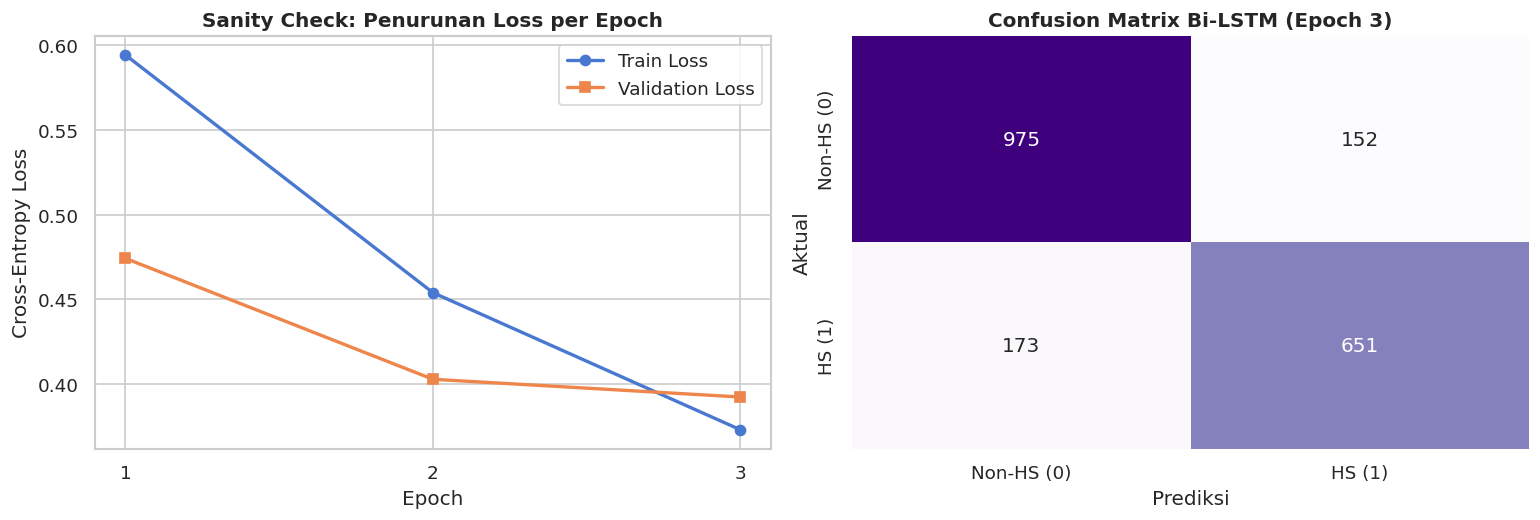

Ringkasan metrik awal DL disimpan ke: D:\TUGAS SEMESTER 5\DATA SCIENCE\id-gov-hatespeech-classification\results\dl_sanity_val_metrics.json


In [5]:
hist_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot Loss Curve
axes[0].plot(hist_df['epoch'], hist_df['train_loss'], marker='o', lw=2, label='Train Loss')
axes[0].plot(hist_df['epoch'], hist_df['val_loss'], marker='s', lw=2, label='Validation Loss')
axes[0].set_title('Sanity Check: Penurunan Loss per Epoch', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].set_xticks(hist_df['epoch'])
axes[0].legend()

# Plot Confusion Matrix Epoch Terakhir
cm = confusion_matrix(y_val_t.numpy(), va_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', ax=axes[1],
            xticklabels=['Non-HS (0)', 'HS (1)'], yticklabels=['Non-HS (0)', 'HS (1)'], cbar=False)
axes[1].set_title(f'Confusion Matrix Bi-LSTM (Epoch {EPOCHS})', fontweight='bold')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

# Simpan ringkasan awal DL
dl_summary = {
    'model_name': 'Deep Learning (Sanity Check): 2-Layer Bi-LSTM',
    'total_params': int(total_params),
    'trainable_params': int(trainable_params),
    'epochs_run': EPOCHS,
    'final_train_loss': float(round(hist_df['train_loss'].iloc[-1], 4)),
    'final_val_loss': float(round(hist_df['val_loss'].iloc[-1], 4)),
    'macro_f1': float(round(hist_df['val_macro_f1'].iloc[-1], 4)),
    'precision_hs': float(round(hist_df['val_prec_hs'].iloc[-1], 4)),
    'recall_hs': float(round(hist_df['val_rec_hs'].iloc[-1], 4)),
    'roc_auc': float(round(hist_df['val_roc_auc'].iloc[-1], 4))
}
out_file = results_dir / 'dl_sanity_val_metrics.json'
with open(out_file, 'w', encoding='utf-8') as f:
    json.dump(dl_summary, f, indent=4)

print(f"Ringkasan metrik awal DL disimpan ke: {out_file}")